# 03 — E2: PCA dimensionality (owner: J)

**Question.** How much retrieval accuracy do we lose when MiniLM's 384-d embeddings are reduced with PCA, and
what do we gain in latency and memory?

**Setting.** FiQA **dev** (500 queries, 57,638 docs), exact `torch_knn`, k = 10, seed 42. PCA is fitted on the
corpus only; queries get the same transform; rows are re-normalized after projection (hard rule 2).
Runs `run_e2_000`–`003` (grid) and `run_e2_004`/`005` (final configs B / A, same session).

**Outputs.** `report/figures/e2_*.pdf` and `report/tables/e2_*.md`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO = Path.cwd().parent                      # run this notebook from notebooks/
sys.path.insert(0, str(REPO / "src"))
from finsight.report import BLUE, INK_2, ORANGE, apply_style, save_figure, save_table

apply_style()
RESULTS = REPO / "experiments" / "results"


def metrics(run_id):
    return json.loads((RESULTS / run_id / "metrics.json").read_text())


grid = [metrics(f"run_e2_00{i}") for i in range(4)]   # 384, 128, 64, 32 dims
grid.sort(key=lambda m: -m["dim"])
base = grid[0]
[(m["dim"], round(m["recall@10"], 4)) for m in grid]

[(384, 0.4665), (128, 0.4412), (64, 0.3671), (32, 0.2686)]

## 1. Variance kept by the first *d* principal components

PCA keeps the directions with the most variance. If retrieval only needed variance, Recall@10 would fall
as fast as the variance curve. We fit our own `PCAReducer` with all 384 components on the cached corpus
embeddings (no download; ~10 s).

In [2]:
from finsight.pca import PCAReducer

emb = np.load(REPO / "data" / "fiqa_corpus_minilm.npy")          # (57,638, 384), L2-normalized
ratio = PCAReducer(384).fit(emb).explained_variance_ratio_      # (384,), descending
cum = np.cumsum(ratio)
kept = {d: float(cum[d - 1]) for d in (32, 64, 128, 384)}
{d: round(v, 3) for d, v in kept.items()}

{32: 0.456, 64: 0.614, 128: 0.795, 384: 1.0}

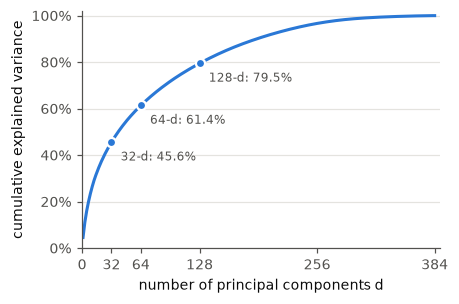

In [3]:
fig, ax = plt.subplots(figsize=(4.2, 2.8))
ax.plot(np.arange(1, 385), cum, color=BLUE)
for d in (32, 64, 128):
    ax.plot(d, kept[d], "o", color=BLUE, markeredgecolor="white", markeredgewidth=1.5, zorder=3)
    ax.annotate(f"{d}-d: {kept[d]:.1%}", (d, kept[d]), xytext=(6, -12), textcoords="offset points",
                color=INK_2, fontsize=8)
ax.set_xlim(0, 390)
ax.set_ylim(0, 1.02)
ax.set_xticks([0, 32, 64, 128, 256, 384])
ax.set_xlabel("number of principal components d")
ax.set_ylabel("cumulative explained variance")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
save_figure(fig, "e2_variance",
            "Cumulative explained variance of PCA fitted on the 57,638 FiQA corpus embeddings "
            "(MiniLM-L6-v2, 384-d). 128 components keep 79.5% of the variance; 32 keep 45.6%.")
plt.show()

## 2. Accuracy vs. dimension, and the accuracy–latency trade-off

Left: both accuracy metrics fall slowly from 384 to 128 dims, then steeply. Right: each point is one PCA
dimension; the further left, the faster; the higher, the more accurate. Memory is in the table below.

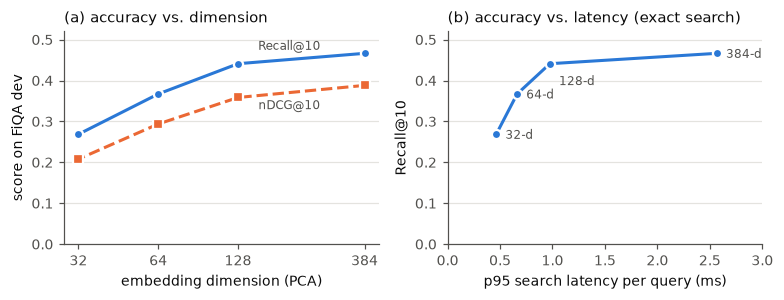

In [4]:
dims = [m["dim"] for m in grid]
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 2.8))

a.plot(dims, [m["recall@10"] for m in grid], "o-", color=BLUE, markeredgecolor="white", markeredgewidth=1.5)
a.plot(dims, [m["ndcg@10"] for m in grid], "s--", color=ORANGE, markeredgecolor="white", markeredgewidth=1.5)
a.text(200, 0.475, "Recall@10", color=INK_2, ha="center", fontsize=8)
a.text(200, 0.33, "nDCG@10", color=INK_2, ha="center", fontsize=8)
a.set_xscale("log", base=2)
a.set_xticks(dims, [str(d) for d in dims])
a.minorticks_off()
a.set_ylim(0, 0.52)
a.set_xlabel("embedding dimension (PCA)")
a.set_ylabel("score on FiQA dev")
a.set_title("(a) accuracy vs. dimension", loc="left")

b.plot([m["latency_p95_ms"] for m in grid], [m["recall@10"] for m in grid], "o-", color=BLUE,
       markeredgecolor="white", markeredgewidth=1.5)
for m in grid:
    b.annotate(f"{m['dim']}-d", (m["latency_p95_ms"], m["recall@10"]), xytext=(6, -14 if m["dim"] == 128 else -3),
               textcoords="offset points", color=INK_2, fontsize=8)
b.set_xlim(0, 3.0)
b.set_ylim(0, 0.52)
b.set_xlabel("p95 search latency per query (ms)")
b.set_ylabel("Recall@10")
b.set_title("(b) accuracy vs. latency (exact search)", loc="left")
fig.tight_layout()
save_figure(fig, "e2_pca_tradeoff",
            "E2, FiQA dev, exact search. (a) Recall@10 and nDCG@10 vs. PCA dimension. (b) Recall@10 vs. p95 "
            "search latency; 128-d loses 2.54 points of Recall@10 for a 2.6x speed-up and 3x less memory.")
plt.show()

In [5]:
rows = [{"Dim": m["dim"], "Variance kept": f"{kept[m['dim']]:.3f}",
         "Recall@10": f"{m['recall@10']:.4f}", "Δ vs 384-d (pt)": f"{(m['recall@10'] - base['recall@10']) * 100:+.2f}",
         "nDCG@10": f"{m['ndcg@10']:.4f}", "p95 (ms)": f"{m['latency_p95_ms']:.3f}",
         "Speed-up": f"{base['latency_p95_ms'] / m['latency_p95_ms']:.1f}×",
         "Memory (MB)": f"{m['index_memory_mb']:.2f}"} for m in grid]
print(save_table(rows, "e2_pca"))

| Dim | Variance kept | Recall@10 | Δ vs 384-d (pt) | nDCG@10 | p95 (ms) | Speed-up | Memory (MB) |
|---|---|---|---|---|---|---|---|
| 384 | 1.000 | 0.4665 | +0.00 | 0.3881 | 2.567 | 1.0× | 84.43 |
| 128 | 0.795 | 0.4412 | -2.54 | 0.3586 | 0.975 | 2.6× | 28.14 |
| 64 | 0.614 | 0.3671 | -9.94 | 0.2937 | 0.663 | 3.9× | 14.07 |
| 32 | 0.456 | 0.2686 | -19.79 | 0.2079 | 0.464 | 5.5× | 7.04 |



## 3. Final configs on dev: A (accurate) vs. B (efficient)

B = 128-d PCA + FAISS IVF (nlist 240, nprobe 16); A = 384-d exact. Both ran in the same session so
latency is comparable (`run_e2_005` = A, `run_e2_004` = B). Chosen in `wiki/decisions/final_configs.md`.

In [6]:
A, B = metrics("run_e2_005"), metrics("run_e2_004")
rows = [{"Config": name, "Dim": m["dim"], "Index": idx, "Recall@10": f"{m['recall@10']:.4f}",
         "nDCG@10": f"{m['ndcg@10']:.4f}", "MRR@10": f"{m['mrr@10']:.4f}",
         "p95 (ms)": f"{m['latency_p95_ms']:.3f}", "Memory (MB)": f"{m['index_memory_mb']:.2f}"}
        for name, m, idx in [("A — accurate", A, "exact"), ("B — efficient", B, "IVF 240 / nprobe 16")]]
print(save_table(rows, "final_configs_dev"))
print(f"B vs A: {(B['recall@10'] - A['recall@10']) * 100:+.2f} pt Recall@10, "
      f"{A['latency_p95_ms'] / B['latency_p95_ms']:.1f}x faster p95, "
      f"{A['index_memory_mb'] / B['index_memory_mb']:.1f}x less memory")

| Config | Dim | Index | Recall@10 | nDCG@10 | MRR@10 | p95 (ms) | Memory (MB) |
|---|---|---|---|---|---|---|---|
| A — accurate | 384 | exact | 0.4665 | 0.3881 | 0.4532 | 2.700 | 84.43 |
| B — efficient | 128 | IVF 240 / nprobe 16 | 0.4178 | 0.3388 | 0.3956 | 0.089 | 28.14 |

B vs A: -4.88 pt Recall@10, 30.2x faster p95, 3.0x less memory


## Findings (J — edit in your own words before the report)

- **128-d is the only reasonable PCA setting:** −2.54 pt Recall@10 for 2.6× faster p95 and 3× less memory.
  Below 128-d the loss grows fast (−9.94 pt at 64-d, −19.79 pt at 32-d).
- **Recall falls less than variance does:** 128-d discards 20.5% of the variance but only 5.4% (relative) of
  Recall@10 — the first discarded directions are mostly noise for retrieval.
- **Speed-up is sub-linear** (3× fewer dims → 2.6×): fixed per-query costs do not shrink with the dimension.
- **PCA + IVF combine:** config B is 30× faster at p95 for −4.88 pt (vs. −5.36 pt if the two losses simply added).
- Caveat: latency from J's machine only; the 384-d p95 varied 2.57–3.48 ms across repeats.